In [80]:
from qiskit.visualization import plot_bloch_vector
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import get_standard_gate_name_mapping
from qiskit.quantum_info import Statevector
from qiskit.converters import circuit_to_dag, dag_to_circuit
import matplotlib.pyplot as plt
import numpy as np
from midiutil import MIDIFile
import mido


# ALL FUNCTIONS:

def vector_xyz(state):
    """
    Function to translate a complex state into a 3D real vector.
    Input: complex state.
    Output: Cartesian x, y, z state.
    """
    # Extract the complex amplitudes (alpha and beta).
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates. 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    return([x, y, z])

    
def vector_spherical(state):
    """
    Function to translate a Cartesian state into spherical coordinates.
    Input: Cartesian x, y, z state.
    Output: spherical r, theta, phi state.
    """
    x, y, z = state

    r = np.sqrt(x**2 + y**2 + z**2)
    if r == 0:
        return [0.0, 0.0, 0.0] # assume central point if r=0.

    # Compute spherical coordinates.
    theta = np.arccos(z / r)
    phi = np.arctan2(y, x)

    return [r, theta, phi]


def spherical_to_cartesian(r, theta, phi):
    """
    Function to translate a spherical state into Cartesian coordinates.
    Inputs: spherical r, theta, phi coordinates.
    Output: Cartesian x, y, z coordinates.
    """
    # Compute Cartesian coordinates.
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    
    return [x, y, z]


def gates(gate_list, qubit_num, qc=None):
    """
    Function to apply a list of gates to a qubit circuit.
    Inputs: user inputted list of gates gate_list and initialised quantum circuit qc.
    Output: list of qubit states and completed quantum circuit.
    """
    # Mapping user inputs onto standard gate methods.
    gate_mapping = get_standard_gate_name_mapping()
    multi_param_names = [ [] for _ in range(qubit_num) ] # create lists for multi-parameter gates.
    states = [ [] for _ in range(qubit_num+1) ] # create lists of qubit states.
    max_qubits_list = [] # create list of qubit numbers required.
    counts = [] # create list of number of gates per qubit.

    # Finding maxmimum qubit number and creating circuit:
    for qubit in range(qubit_num):
        count = 0
        for gate_name in gate_list[qubit]:
            if gate_name in gate_mapping:
                count += 1
                # Check how many parameters this specific gate expects.
                param_num = len(gate_mapping[gate_name].params)
                multi_param_names[qubit].append(param_num) # add to multi-parameter gate operations.
        counts.append(count)
        
    # Initialise the quantum circuit with the required number of qubits +1.
    if qc is None:
        qc = QuantumCircuit(qubit_num+1) # automatically 0-state initialised.

    # Find maximum number of gates for any qubit:
    most_gates = max(counts)
    # Take all parameters for each qubit.
    params = multi_param_gates(multi_param_names, qubit_num, gate_list)

    # Parse through all qubits and compile each gate in synch:
    for i in range(most_gates):
        for qubit in range(qubit_num):
             
            # If qubit has fewer gates than maximum number of gates, add placeholder.
            if counts[qubit] << i:
                gate_list[qubit].append("0")
        
            gate_name = gate_list[qubit][i]
            # Apply the standardised gates.
            if hasattr(qc, gate_name):
                # Determine how many qubits this gate method requires
                if gate_name in gate_mapping:
                    num_gate_qubits = gate_mapping[gate_name].num_qubits                
                else:
                    num_gate_qubits = 1 

                # Target current qubit (and possibly next qubit):
                if num_gate_qubits == 1:
                   target_qubits = [qubit]
                elif num_gate_qubits == 2:
                    target_qubits = [qubit, qubit+1] # spare qubit allows control gates for any intended qubit.
                gate_method = getattr(qc, gate_name)

                # For gates without extra parameters:
                if multi_param_names[qubit][i] == 0: 
                        # Call the method unpacking the precise amount of qubits.
                        gate_method(*target_qubits)
                        
                # For gates with extra parameters:
                elif multi_param_names[qubit][i] == 1:
                    # Unpack maximum 4 possible parameters.
                    param0, = params[qubit][i]
                    gate_method(param0, *target_qubits)
                elif multi_param_names[qubit][i] == 2:
                    param0, param1 = params[qubit][i]
                    gate_method(param0, param1, *target_qubits)
                elif multi_param_names[qubit][i] == 3:
                    param0, param1, param2 = params[qubit][i]
                    gate_method(param0, param1, param2, *target_qubits)
                elif multi_param_names[qubit][i] == 4:
                    param0, param1, param2, param3 = params[qubit][i]
                    gate_method(param0, param1, param2, param3, *target_qubits)

                # Calculate and append state tracking.
                state = vector_xyz(Statevector(qc))
                states[qubit].append(state)
                
            elif gate_name != "0":
                print(f"Warning: Gate '{gate_name}' is not a recognized Qiskit method.")

    # Remove empty list if spare qubit not used.
    cleaned_states = [sublist for sublist in states if sublist]
    
    # AI USAGE: CHATGPT USED TO GENERATE DICTIONARY GIVEN PROMPT: 
    # Remove idle qubits from circuit qc on qiskit and return circuit.

    # Convert to DAG, remove idle wires, and convert back
    dag = circuit_to_dag(qc)
    idle_wires = list(dag.idle_wires())
    for wire in idle_wires:
        dag.remove_qubits(wire)
    
    clean_qc = dag_to_circuit(dag)
    
    return cleaned_states, clean_qc


def get_closest(target, target_dict):
    """
    Function to find the closest key's value based on a midpoint range.
    Inputs: coordinate to find closest value of, and coordinate's dictionary.
    Output: integer closest note value.
    """
    keys_array = np.array(list(target_dict.keys()))
    values_array = np.array(list(target_dict.values())) # list of possible values.
    
    # Find the index of the key with the smallest absolute distance.
    closest_idx = np.abs(keys_array - target).argmin()
    
    return int(values_array[closest_idx]) # pull same index from values list.


def update(state_idx, states):
    """
    Function to change the animation to the next frame.
    Inputs: frame index based on matching note durations state_idx and list of states.
    """
    b.vectors = []  # clear previous frame vector paths cleanly.
    moving_vector = states[state_idx] # vector location in frame.
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    gate_color = ["#000000"]  # high-contrast black for the moving gate vector.
    b.vector_color = background_colors + gate_color
    b.vector_width = background_width
    
    # Render the combined canvas scene.
    b.sphere_color = "#DCE7F2"
    b.sphere_alpha = 0.1
    b.render()
        

def theta_and_phi(states):
    """
    Function to combine theta and phi information.
    Input: list of states.
    Output: list of integer notes.
    """
    notes = [ [] for _ in range(len(states)) ] # create lists of qubit notes.
    
    for i in range(len(states)):
        for j in range(len(states[i])):
            theta = vector_spherical(states[i][j])[1]
            phi = vector_spherical(states[i][j])[2]
    
            # Wrap phi from [-pi, pi] into [0, 2*pi) to match phi_dict.
            phi = phi % (2 * np.pi)
            if np.isclose(phi, 2 * np.pi, atol=1e-4):
                phi = 0.0 # avoid rounding errors.

            # Find exact or closest pitch.
            if theta in theta_dict:
                theta_note = theta_dict[theta]
            else:
                theta_note = get_closest(theta, theta_dict)
                
            if phi in phi_dict:
                phi_note = phi_dict[phi]
            else:
                phi_note = get_closest(phi, phi_dict)

            note = ((theta_note - 1) * 12) + phi_note # combine octave and note using MIDI note convention.
            notes[i].append(note)
        
    return notes

    
def multi_param_gates(multi_param_names, qubit_num, gate_list):
    """
    Function to allow user input for multi-parameter gates.
    Inputs: names of gates requiring extra parameters multi_param_names, number of qubits, and list of gates to apply.
    Output: float extra paramaters.
    """
    params = [ [] for _ in range(qubit_num) ]

    for j in range(len(multi_param_names)):
        for i in range(len(multi_param_names[j])): 
            if multi_param_names[j][i] != 0:
                # Validate parameter input:
                while True:
                    params0 = str(input(f"Please enter required parameters for qubit {j+1} {gate_list[j][i]}, separated by spaces."))
                    params0 = list(params0.split(' '))
                    if len(params0) == multi_param_names[j][i] and any(item.isalpha() for item in params0) == False: # check numerical and right number.
                        break
                    print(f"Please enter {multi_param_names[j][i]} numerical parameter(s).")
                    
                for a in range(len(params0)):
                    params0[a] = float(params0[a]) # convert items to float.
                    
                params[j].append(params0)

            else:
                params[j].append("X")
    return params



def setup():
    """
    Setup input prompts and validation.
    Outputs: desired number of qubits qubit_num, instruments instrument_list, tempo, and qubit gates for each qubit all_qubit_gates.
    """
    # Inputs and validations.
    all_qubit_gates = []
    
    # Qubit number.
    while True:
        try:
            qubit_num = int(input("Please input integer number of qubits desired."))
            if qubit_num > 0:  # ensure a positive number of qubits.
                break
            print("Please enter a positive integer.")
        except ValueError:
            print("Invalid input. Please enter a whole number.") # ensure a whole number.
    
    # Instrument.
    while True:
    # If invalid instruments are chosen, piano is used as default.
        instrument_names = str(input("Please input instruments as desired for each qubit, separated by spaces."))
        instrument_list = instrument_names.split(' ')
        if len(instrument_list) == qubit_num:  # ensure equal numbers of instruments and qubits.
            break
        print("Please enter the same numbers of instruments as qubits.")
    
    # Tempo.
    while True:
        try:
            tempo = int(input("Please enter composition tempo."))
            if 0 < tempo < 240:  # ensure a positive tempo.
                break
            print("Please enter a positive integer up to 240.")
        except ValueError:
            print("Invalid input. Please enter a whole number.") # ensure a whole number.
    
    for x in range(qubit_num):
        # Invalid gates are removed by gates function.
        gate_list = str(input(f"Please input gates as required for qubit {x+1}, separated by spaces."))
        all_qubit_gates.append(gate_list.split(' '))

    return qubit_num, instrument_list, tempo, all_qubit_gates



def make_MIDI(qubit_num, notes, instrument_list, instrument_dict, duration_dict, tempo):
    """
    Function to create MIDI audio file.
    Input: number of qubits qubit_num, notes played by each qubit, instruments instruments_list, durations durations_dict, and tempo.
    Output: completed MyMIDI object and duration lengths in seconds.
    """
    MyMIDI = MIDIFile(qubit_num) # create MIDI file with track number = qubit number.
    lengths = [ [] for _ in range(qubit_num) ] # create lists for lengths in each qubit.
    
    for x in range(qubit_num):
        # Build the audio:
        track = x # 0-indexed tracks for each note sequence.
        channel = x # 0-indexed channels for each instrument.
        time = 0
        current_time = 0 # monitor current location in music.

        # Validate volume input.
        while True:
            try:
                volume = int(input(f"Please enter volume (0 - 127) for qubit {x+1}.")) # 0-127, 127 being full volume.
                if 0 < tempo < 127:  # ensure a positive tempo.
                    break
                print("Please enter a positive integer up to 127.")
            except ValueError:
                print("Invalid input. Please enter a whole number.") # ensure a whole number.
    
        # Find instrument in dictionary and apply to channel.
        if instrument_list[x] in instrument_dict:
            instrument = instrument_dict[instrument_list[x]]
        else:
            print("Invalid instrument.")
            instrument = 0 # default instrument of piano.
        MyMIDI.addProgramChange(track,channel,time,instrument)

        # Create track with tempo.
        MyMIDI.addTrackName(track, time, f"track {x}")
        MyMIDI.addTempo(track, time, tempo)

        # User input note duration names.
        while True:
            # If invalid durations are chosen, 1 beat is used as default.
            duration_names = input(f"Please enter {len(notes[x])} note types for qubit {x+1}, separated by spaces.")
            duration_list = duration_names.split(' ')
            if len(duration_list) == len(notes[x]):  # ensure equal numbers of durations and notes.
                break
            print("Please enter the same numbers of durations as notes.")

        for i in range(len(notes[x])):
            pitch = notes[x][i]
        
            if duration_list[i] in duration_dict:
                duration = duration_dict[duration_list[i]] # find durations in dictionary and apply to notes.
            else:
                print("Invalid duration.")
                duration = 1 # default duration of 1.
        
            MyMIDI.addNote(track,channel,pitch,current_time,duration,volume) # add note to track.
            current_time += duration # increase current time based on note duration.
            lengths[x].append(60 * duration / tempo) # BPM durations to seconds. 

    return MyMIDI, lengths



# DICTIONARIES:

# Create dictionaries to map state (r, theta, phi) to integer pitch over middle 7 octaves.
phi_dict = {}
theta_dict = {}
# Assumes normalised state with r = 1.

# Theta => octaves (7 in total).
theta_dict = {
    (np.pi * 1 / 8): 1,
    (np.pi * 2 / 8): 2,
    (np.pi * 3 / 8): 3,
    (np.pi * 4 / 8): 4,
    (np.pi * 5 / 8): 5,
    (np.pi * 6 / 8): 6,
    (np.pi * 7 / 8): 7
}

# Phi values relating to 12 notes in first usable octave, C pitch = 24.
for j in range(24, 36): # phi = > notes.
    phi_dict.update({(((j - 24) / 6) * np.pi) : j})

# Dictionary to map note types to length in beats.
duration_dict = {
    "breve": 8,
    "semibreve": 4,
    "minim": 2,
    "crotchet": 1,
    "quaver": 0.5,
    "semiquaver": 0.25,
    "demisemiquaver": 0.125
}


In [81]:
# AI USAGE: CHATGPT USED TO GENERATE DICTIONARY GIVEN PROMPT: 
# Please format the MIDI (midiutil) instrument channel list as python dictionary. User types name of instrument (no capitals) to equate to the code number 0-indexed.
# Some percussive options have since been removed.

# Dictionary to map instruments to code numbers.
instrument_dict = {
    # Piano (0-7)
    "piano": 0,
    "bright-acoustic-piano": 1,
    "electric-grand-piano": 2,
    "honky-tonk-piano": 3,
    "electric-piano-1": 4,
    "electric-piano-2": 5,
    "harpsichord": 6,
    "clavinet": 7,

    # Chromatic Percussion (8-15)
    "celesta": 8,
    "glockenspiel": 9,
    "music-box": 10,
    "vibraphone": 11,
    "marimba": 12,
    "xylophone": 13,
    "tubular-bells": 14,
    "dulcimer": 15,

    # Organ (16-23)
    "drawbar-organ": 16,
    "percussive-organ": 17,
    "rock-organ": 18,
    "church-organ": 19,
    "reed-organ": 20,
    "accordion": 21,
    "harmonica": 22,
    "tango-accordion": 23,

    # Guitar (24-31)
    "acoustic-guitar-nylon": 24,
    "nylon-guitar": 24,
    "acoustic-guitar-steel": 25,
    "steel-guitar": 25,
    "electric-guitar-jazz": 26,
    "jazz-guitar": 26,
    "electric-guitar-clean": 27,
    "clean-guitar": 27,
    "electric-guitar-muted": 28,
    "muted-guitar": 28,
    "overdriven-guitar": 29,
    "distortion-guitar": 30,
    "guitar-harmonics": 31,

    # Bass (32-39)
    "acoustic-bass": 32,
    "electric-bass-finger": 33,
    "bass-finger": 33,
    "electric-bass-pick": 34,
    "bass-pick": 34,
    "fretless-bass": 35,
    "slap-bass-1": 36,
    "slap-bass-2": 37,
    "synth-bass-1": 38,
    "synth-bass-2": 39,

    # Strings (40-47)
    "violin": 40,
    "viola": 41,
    "cello": 42,
    "contrabass": 43,
    "double-bass": 43,
    "tremolo-strings": 44,
    "pizzicato-strings": 45,
    "orchestral-harp": 46,
    "harp": 46,
    "timpani": 47,

    # Ensemble (48-55)
    "string-ensemble-1": 48,
    "strings": 48,
    "string-ensemble-2": 49,
    "synth-strings-1": 50,
    "synth-strings-2": 51,
    "choir-aahs": 52,
    "choir": 52,
    "voice-oohs": 53,
    "synth-voice": 54,
    "orchestra-hit": 55,

    # Brass (56-63)
    "trumpet": 56,
    "trombone": 57,
    "tuba": 58,
    "muted-trumpet": 59,
    "french-horn": 60,
    "brass-section": 61,
    "synth-brass-1": 62,
    "synth-brass-2": 63,

    # Reed (64-71)
    "soprano-sax": 64,
    "alto-sax": 65,
    "sax": 65,
    "tenor-sax": 66,
    "baritone-sax": 67,
    "oboe": 68,
    "english-horn": 69,
    "bassoon": 70,
    "clarinet": 71,

    # Pipe (72-79)
    "piccolo": 72,
    "flute": 73,
    "recorder": 74,
    "pan-flute": 75,
    "blown-bottle": 76,
    "shakuhachi": 77,
    "whistle": 78,
    "ocarina": 79,

    # Ethnic (104-111)
    "sitar": 104,
    "banjo": 105,
    "shamisen": 106,
    "koto": 107,
    "kalimba": 108,
    "bagpipe": 109,
    "fiddle": 110,
    "shanai": 111,
}


(-0.9, 0.9)

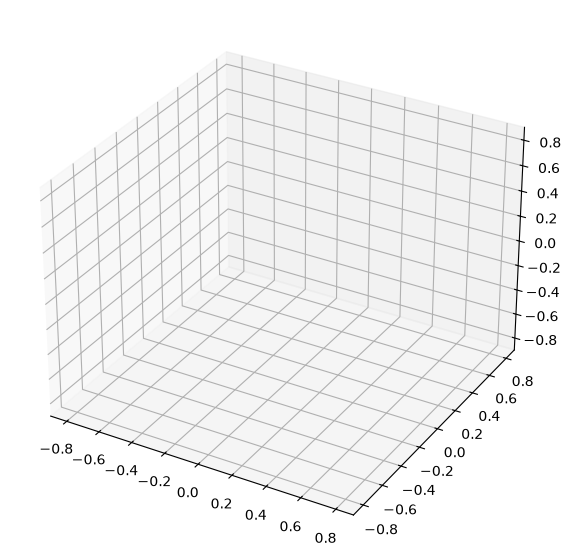

In [82]:
# Set up a 3D canvas, Bloch sphere, background musical vectors.

fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)
b.plot_axes_labels = lambda: None # hide axes labels.

# Arrays for notes and colour mapping.
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
octave_colours = [plt.colormaps["turbo_r"](val) for val in np.linspace(0, 1, 12)]

# Assign even spaced locations for each musical vector arrow.
octave = {}
for i in range(0, 12):
    r = 1
    theta = np.pi / 2 # octave at circumference.
    phi = (i / 6) * np.pi
    x, y, z = spherical_to_cartesian(r, theta, phi)
            
    octave[notes[i]] = [x, y, z]
    
# Sequentially add vectors and text annotations.
for label, coords in octave.items():
    b.add_vectors(coords)
        
    # Move labels 15% away from the sphere's centre.
    label_coords = 1.15 * np.array(coords)
    b.add_annotation(label_coords, label)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = octave_colours
background_width = 3

# Set up padding boundaries.
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)
(-0.9, 0.9)

In [83]:
qubit_num, instrument_list, tempo, all_qubit_gates = setup()
states, qc = gates(all_qubit_gates, qubit_num)
notes = theta_and_phi(states)
print(notes)
MyMIDI, lengths = make_MIDI(len(notes), notes, instrument_list, instrument_dict, duration_dict, tempo)

# Save as MIDI:
MIDI_path = "bloch_midi_1.2.midi"
with open(MIDI_path, 'wb') as output_file:
    MyMIDI.writeFile(output_file)

Please input integer number of qubits desired. 2
Please input instruments as desired for each qubit, separated by spaces. steel-guitar bass-pick
Please enter composition tempo. 86
Please input gates as required for qubit 1, separated by spaces. u u u u u u u u u u u u
Please input gates as required for qubit 2, separated by spaces. u u u u u u u u u
Please enter required parameters for qubit 1 u, separated by spaces. 1.570796 4.712389 0.000000
Please enter required parameters for qubit 1 u, separated by spaces. 0.000000 4.712389 -4.712389
Please enter required parameters for qubit 1 u, separated by spaces. 0.392699 1.047198 -4.712389
Please enter required parameters for qubit 1 u, separated by spaces. 0.000000 2.094395 -1.047198
Please enter required parameters for qubit 1 u, separated by spaces. 0.000000 2.617994 -2.094395
Please enter required parameters for qubit 1 u, separated by spaces. 0.000000 2.094395 -2.617994
Please enter required parameters for qubit 1 u, separated by spaces

[[69, 69, 74, 76, 77, 76, 74, 76, 74, 72, 74, 69], [69, 69, 74, 76, 77, 76, 74, 76, 74]]


Please enter volume (0 - 127) for qubit 1. 100
Please enter 12 note types for qubit 1, separated by spaces. minim minim crotchet crotchet crotchet quaver quaver minim quaver crotchet quaver minim
Please enter volume (0 - 127) for qubit 2. 70
Please enter 9 note types for qubit 2, separated by spaces. minim minim minim minim minim minim crotchet crotchet minim


In [84]:
# Build animation timeline to match note durations:
animations = [] # create list to store each qubit's Bloch animation.

for z in range(qubit_num):
    base_step = min(lengths[z])
    timeline = []
    # Repeat frames as durations require.
    for state_idx, length in enumerate(lengths[z]):
        repeats = int(round(length / base_step))
        timeline.extend([state_idx] * repeats)
    
    # Build the animation:
    ani = FuncAnimation(fig, update, frames=timeline, fargs=(states[z],), interval=base_step, blit=False)
    animations.append(ani) # store each qubit animation.

# Save as separate GIFs:
for index, ani in enumerate(animations):
    gif_path = f"bloch_anim_1.2_q{index+1}.gif"
    ani.save(gif_path, writer='pillow', fps=1/base_step)
plt.close(fig)

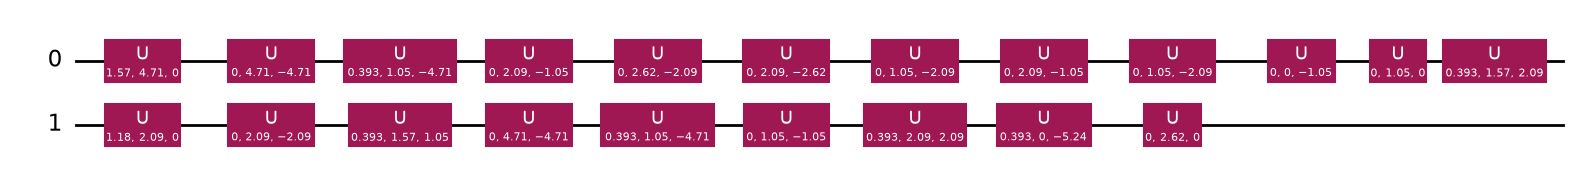

In [85]:
qc.draw('mpl')